### Ableitungsregeln: e-Funktion, Produkt-, Ketten- und Quotientenregel - Übungen

In der Kursstufe kommen neue Funktionen dazu: die **e-Funktion**, der **natürliche Logarithmus** und Sinusfunktionen mit Parametern.
Für zusammengesetzte Funktionen brauchst du neue **Ableitungsregeln**: Produktregel, Kettenregel und (im Leistungsfach) Quotientenregel.
Am Ende geht es um Tangenten und um das Verhalten von Funktionen für x → ±∞ (Asymptoten).

Leite immer zuerst **von Hand** ab und prüfe dann mit `diff()`. sympy schreibt Ergebnisse oft anders auf als du (z. B. ausmultipliziert
oder anders sortiert); mit `factor()` und `simplify()` bekommst du eine Form zum Vergleichen.

Vorausgesetzt wird das Notebook *Ableitungen* (Klasse 10). Abschnitte und Aufgaben, die nur im **Leistungsfach** vorkommen, sind markiert.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Unter den meisten Aufgaben steht das **erwartete Ergebnis**.

**Brüche und Kommazahlen:** Python rechnet `1/6` oder `0.5` sofort als Kommazahl, bevor sympy die Zahl sieht.
Die erwarteten Ausgaben sind aber mit exakten Brüchen berechnet. Schreibe solche Zahlen deshalb mit `Rational`: `Rational(1, 6)` für 1/6,
`Rational('0.5')` für 0,5. Bei einer Division ganzer Zahlen genügt es, eine davon mit `Integer` zu schreiben: `Integer(1) / 6`.
Aufgaben, bei denen das nötig ist, haben einen entsprechenden Hinweis.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### sympy laden

**Führe diese Zelle zuerst aus** (und nach jedem Neustart des Kernels wieder). Sie lädt sympy und matplotlib, schaltet die Formel-Ausgabe ein
und legt die Variable `x` und die Parameter `a`, `b`, `c`, `d`, `k`, `u` an. `real=True` sagt sympy, dass es reelle Zahlen sind:
Dann sucht `solve()` nur reelle Lösungen und vereinfacht z. B. ln(eˣ) zu x.

In [ ]:
from sympy import *
init_printing()
import matplotlib.pyplot as plt
x = symbols('x', real=True)
a, b, c, d, k, u = symbols('a b c d k u', real=True)

## 1. Die e-Funktion und der natürliche Logarithmus

#### `exp(x)` und `log(x)`

Die **natürliche Exponentialfunktion** f(x) = eˣ (e ≈ 2,718) ist in sympy `exp(x)`. Ihre besondere Eigenschaft:
**Sie ist ihre eigene Ableitung**, (eˣ)' = eˣ.

Der **natürliche Logarithmus** ln(x) ist die Umkehrung: ln(eˣ) = x und e^(ln x) = x (für x > 0). In sympy heißt er `log(x)`
(ohne Basis). Damit löst du Exponentialgleichungen: eˣ = 5 ⟺ x = ln 5.

In [ ]:
display(diff(exp(x), x))
display(exp(1), N(exp(1), 10))
display(simplify(log(exp(x))))
display(solve(Eq(exp(x), 5), x))
plot(exp(x), log(x), (x, -3, 4), ylim=(-3, 5), legend=True);

#### Logarithmusgesetze

| Gesetz | sympy |
|---|---|
| ln(a·b) = ln a + ln b | `expand_log(log(a*b), force=True)` |
| ln(a/b) = ln a − ln b | |
| ln(aʳ) = r·ln a | |
| aˣ = e^(x·ln a) | jede Exponentialfunktion lässt sich mit e schreiben |

`expand_log(..., force=True)` wendet die Gesetze an (`force=True`, weil sie nur für positive Zahlen gelten),
`logcombine(..., force=True)` fasst wieder zusammen.

In [ ]:
display(expand_log(log(a**2 * b), force=True))
display(logcombine(log(a) - 2*log(b), force=True))
display(N(log(8) / log(2)))
simplify(exp(x * log(2)))

#### Aufgabe 1.1

Gib e³ und e⁻¹ genau und mit 5 Ziffern aus.

**Erwartete Ausgabe:**

$\displaystyle e^{3}$

$\displaystyle 20.086$

$\displaystyle e^{-1}$

$\displaystyle 0.36788$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(exp(3), N(exp(3), 5))
display(exp(-1), N(exp(-1), 5))
```

</details>

#### Aufgabe 1.2

Löse eˣ = 20 exakt und gib die Lösung auch mit 4 Ziffern aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ \log{\left(20 \right)}\right]$

$\displaystyle 2.996$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = solve(Eq(exp(x), 20), x)
display(l)
N(l[0], 4)
```

</details>

#### Aufgabe 1.3

Löse e^(2x − 1) = 7 exakt.

**Erwartete Ausgabe:**

$\displaystyle \left[ \frac{1}{2} + \frac{\log{\left(7 \right)}}{2}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solve(Eq(exp(2*x - 1), 7), x)
```

</details>

#### Aufgabe 1.4

Löse 3·e^(−0,5x) = 1,2 exakt und mit 4 Ziffern (schreibe 0,5 und 1,2 als `Rational`).

**Erwartete Ausgabe:**

$\displaystyle \left[ \log{\left(\frac{25}{4} \right)}\right]$

$\displaystyle 1.833$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = solve(Eq(3 * exp(-Rational(1, 2) * x), Rational(6, 5)), x)
display(l)
N(l[0], 4)
```

</details>

#### Aufgabe 1.5

Löse e²ˣ − 5eˣ + 6 = 0 (reelle Lösungsmenge mit `solveset`). Tipp für die Rechnung von Hand: Substitution u = eˣ.

**Erwartete Ausgabe:**

$\displaystyle \left\{\log{\left(2 \right)}, \log{\left(3 \right)}\right\}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solveset(Eq(exp(2*x) - 5*exp(x) + 6, 0), x, S.Reals)
```

</details>

#### Aufgabe 1.6

Löse ln(x) = 2 und ln(3x − 1) = 0.

**Erwartete Ausgabe:**

$\displaystyle \left[ e^{2}\right]$

$\displaystyle \left[ \frac{2}{3}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(solve(Eq(log(x), 2), x))
solve(Eq(log(3*x - 1), 0), x)
```

</details>

#### Aufgabe 1.7

Fasse `log(a) + 3*log(b) - log(c)` zu einem Logarithmus zusammen.

**Erwartete Ausgabe:**

$\displaystyle \log{\left(\frac{a b^{3}}{c} \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
logcombine(log(a) + 3*log(b) - log(c), force=True)
```

</details>

#### Aufgabe 1.8

Zerlege ln(a³·√b / c) mit den Logarithmusgesetzen.

**Erwartete Ausgabe:**

$\displaystyle 3 \log{\left(a \right)} + \frac{\log{\left(b \right)}}{2} - \log{\left(c \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
expand_log(log(a**3 * sqrt(b) / c), force=True)
```

</details>

#### Aufgabe 1.9

Schreibe 2ˣ und 0,5ˣ als e-Funktion: Gib `exp(x*log(2))` und `exp(x*log(Rational(1, 2)))` aus und prüfe mit `simplify(... - 2**x)`, dass sie gleich 2ˣ bzw. 0,5ˣ sind.

**Erwartete Ausgabe:**

$\displaystyle e^{x \log{\left(2 \right)}}$

$\displaystyle e^{- x \log{\left(2 \right)}}$

$\displaystyle 0$

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(exp(x*log(2)), exp(x*log(Rational(1, 2))))
display(simplify(exp(x*log(2)) - 2**x))
simplify(exp(x*log(Rational(1, 2))) - Rational(1, 2)**x)
```

</details>

#### Aufgabe 1.10

Zeichne die Graphen von eˣ, e⁻ˣ und 2·eˣ für −2 ≤ x ≤ 2 in ein Diagramm (mit Legende).

**Erwartete Ausgabe:**



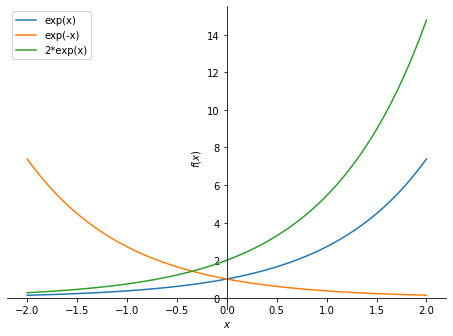

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(exp(x), exp(-x), 2*exp(x), (x, -2, 2), legend=True);
```

</details>

#### Aufgabe 1.11

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(exp(0))
display(log(1))
display(log(E))
display(exp(log(7)))
log(exp(3))
```

In [ ]:
display(exp(0))
display(log(1))
display(log(E))
display(exp(log(7)))
log(exp(3))

## 2. Die Produktregel

#### (u · v)' = u' · v + u · v'

Ist eine Funktion ein **Produkt** zweier Funktionen u(x) und v(x), dann gilt die **Produktregel**:

f(x) = u(x) · v(x) ⟹ f'(x) = u'(x) · v(x) + u(x) · v'(x)

Beispiel: f(x) = x² · eˣ mit u = x², v = eˣ, also u' = 2x, v' = eˣ:
f'(x) = 2x · eˣ + x² · eˣ = (x² + 2x) · eˣ. Bei e-Funktionen klammert man eˣ aus; das macht `factor()`.

In [ ]:
u = x**2
v = exp(x)
display(diff(u, x) * v + u * diff(v, x))
display(diff(u * v, x))
factor(diff(u * v, x))

#### Aufgabe 2.1

Leite f(x) = x · eˣ ab (mit `factor()` ausgeklammert).

**Erwartete Ausgabe:**

$\displaystyle \left(x + 1\right) e^{x}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
factor(diff(x * exp(x), x))
```

</details>

#### Aufgabe 2.2

Leite f(x) = x² · sin(x) ab.

**Erwartete Ausgabe:**

$\displaystyle x^{2} \cos{\left(x \right)} + 2 x \sin{\left(x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(x**2 * sin(x), x)
```

</details>

#### Aufgabe 2.3

Leite f(x) = (2x + 1) · eˣ ab und klammere aus.

**Erwartete Ausgabe:**

$\displaystyle \left(2 x + 3\right) e^{x}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
factor(diff((2*x + 1) * exp(x), x))
```

</details>

#### Aufgabe 2.4

Leite f(x) = x³ · e⁻ˣ ab und klammere aus.

**Erwartete Ausgabe:**

$\displaystyle - x^{2} \left(x - 3\right) e^{- x}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
factor(diff(x**3 * exp(-x), x))
```

</details>

#### Aufgabe 2.5

Leite f(x) = sin(x) · cos(x) ab.

**Erwartete Ausgabe:**

$\displaystyle - \sin^{2}{\left(x \right)} + \cos^{2}{\left(x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(sin(x) * cos(x), x)
```

</details>

#### Aufgabe 2.6

Leite f(x) = eˣ · cos(x) ab und klammere aus.

**Erwartete Ausgabe:**

$\displaystyle \left(- \sin{\left(x \right)} + \cos{\left(x \right)}\right) e^{x}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
factor(diff(exp(x) * cos(x), x))
```

</details>

#### Aufgabe 2.7

Rechne die Produktregel für f(x) = (x² − 1) · eˣ Schritt für Schritt nach: Lege `u` und `v` an, gib `u'` und `v'` aus und dann
`u'·v + u·v'` mit `factor()`.

**Erwartete Ausgabe:**

$\displaystyle 2 x$

$\displaystyle e^{x}$

$\displaystyle \left(x^{2} + 2 x - 1\right) e^{x}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
u = x**2 - 1
v = exp(x)
display(diff(u, x), diff(v, x))
factor(diff(u, x) * v + u * diff(v, x))
```

</details>

#### Aufgabe 2.8

Leite f(x) = x · ln(x) ab. **(Leistungsfach: (ln x)' = 1/x)**

**Erwartete Ausgabe:**

$\displaystyle \log{\left(x \right)} + 1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(x * log(x), x)
```

</details>

#### Aufgabe 2.9

Bilde f' und f'' von f(x) = x · eˣ (beide ausgeklammert). Gib dann f⁽¹⁰⁾ aus.

**Erwartete Ausgabe:**

$\displaystyle \left(x + 1\right) e^{x}$

$\displaystyle \left(x + 2\right) e^{x}$

$\displaystyle \left(x + 10\right) e^{x}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x * exp(x)
display(factor(diff(f, x)), factor(diff(f, x, 2)))
factor(diff(f, x, 10))
```

</details>

#### Aufgabe 2.10

Für welche x hat f(x) = x · e⁻ˣ eine waagrechte Tangente? Löse f'(x) = 0.

**Erwartete Ausgabe:**

$\displaystyle \left[ 1\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solve(diff(x * exp(-x), x), x)
```

</details>

#### Aufgabe 2.11

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(diff(x * x, x))
display(diff(5 * exp(x), x))
diff(x * sin(x), x)
```

In [ ]:
display(diff(x * x, x))
display(diff(5 * exp(x), x))
diff(x * sin(x), x)

## 3. Die Kettenregel

#### Äußere mal innere Ableitung

Bei einer **Verkettung** f(x) = u(v(x)) steckt eine Funktion in einer anderen, z. B. f(x) = e^(3x) (außen eᵘ, innen 3x)
oder f(x) = (x² + 1)⁵ (außen u⁵, innen x² + 1). Es gilt die **Kettenregel**:

f'(x) = u'(v(x)) · v'(x) — „äußere Ableitung mal innere Ableitung“

Wichtige Sonderfälle: (e^(kx))' = k · e^(kx), (sin(kx))' = k · cos(kx), ((ax + b)ⁿ)' = n·a·(ax + b)ⁿ⁻¹.

Mit sympy kannst du die Kettenregel nachrechnen: Schreibe die äußere Funktion mit `u`, leite nach `u` ab und setze mit `subs` die innere ein.

In [ ]:
display(diff(exp(3*x), x))
display(diff((x**2 + 1)**5, x))
aussen = u**5
innen = x**2 + 1
diff(aussen, u).subs(u, innen) * diff(innen, x)

#### Aufgabe 3.1

Leite f(x) = e^(5x) ab.

**Erwartete Ausgabe:**

$\displaystyle 5 e^{5 x}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(exp(5*x), x)
```

</details>

#### Aufgabe 3.2

Leite f(x) = e^(−x²) ab.

**Erwartete Ausgabe:**

$\displaystyle - 2 x e^{- x^{2}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(exp(-x**2), x)
```

</details>

#### Aufgabe 3.3

Leite f(x) = (3x − 2)⁴ ab.

**Erwartete Ausgabe:**

$\displaystyle 12 \left(3 x - 2\right)^{3}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff((3*x - 2)**4, x)
```

</details>

#### Aufgabe 3.4

Leite f(x) = sin(2x) und g(x) = cos(πx) ab.

**Erwartete Ausgabe:**

$\displaystyle 2 \cos{\left(2 x \right)}$

$\displaystyle - \pi \sin{\left(\pi x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(diff(sin(2*x), x))
diff(cos(pi*x), x)
```

</details>

#### Aufgabe 3.5

Leite f(x) = √(x² + 1) ab.

**Erwartete Ausgabe:**

$\displaystyle \frac{x}{\sqrt{x^{2} + 1}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(sqrt(x**2 + 1), x)
```

</details>

#### Aufgabe 3.6

Leite f(x) = 1/(2x + 1) ab. (Schreibe (2x + 1)⁻¹ und verwende die Kettenregel.)

**Erwartete Ausgabe:**

$\displaystyle - \frac{2}{\left(2 x + 1\right)^{2}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(1 / (2*x + 1), x)
```

</details>

#### Aufgabe 3.7

Leite f(x) = sin²(x) = (sin x)² ab.

**Erwartete Ausgabe:**

$\displaystyle 2 \sin{\left(x \right)} \cos{\left(x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(sin(x)**2, x)
```

</details>

#### Aufgabe 3.8

Leite f(x) = 4 · e^(−0,2x) + 1 ab (0,2 als `Rational`).

**Erwartete Ausgabe:**

$\displaystyle - \frac{4 e^{- \frac{x}{5}}}{5}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(4 * exp(-Rational(1, 5) * x) + 1, x)
```

</details>

#### Aufgabe 3.9

Leite f(x) = e^(kx) nach x ab (k ist ein Parameter).

**Erwartete Ausgabe:**

$\displaystyle k e^{k x}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(exp(k*x), x)
```

</details>

#### Aufgabe 3.10

Rechne die Kettenregel für f(x) = e^(x² − 3x) wie im Beispiel nach: äußere Funktion `exp(u)`, innere `x**2 - 3*x`.

**Erwartete Ausgabe:**

$\displaystyle \left(2 x - 3\right) e^{x^{2} - 3 x}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
aussen = exp(u)
innen = x**2 - 3*x
diff(aussen, u).subs(u, innen) * diff(innen, x)
```

</details>

#### Aufgabe 3.11

Leite f(x) = ln(x² + 1) ab. **(Leistungsfach)**

**Erwartete Ausgabe:**

$\displaystyle \frac{2 x}{x^{2} + 1}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(log(x**2 + 1), x)
```

</details>

#### Aufgabe 3.12

Leite f(x) = x · e^(−2x) ab (Produkt- **und** Kettenregel) und klammere aus.

**Erwartete Ausgabe:**

$\displaystyle - \left(2 x - 1\right) e^{- 2 x}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
factor(diff(x * exp(-2*x), x))
```

</details>

#### Aufgabe 3.13

Leite f(x) = (x + 1)² · e^(−x) ab und klammere aus.

**Erwartete Ausgabe:**

$\displaystyle - \left(x - 1\right) \left(x + 1\right) e^{- x}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
factor(diff((x + 1)**2 * exp(-x), x))
```

</details>

#### Aufgabe 3.14

Bilde f' und f'' von f(x) = e^(−x²) (ausgeklammert).

**Erwartete Ausgabe:**

$\displaystyle - 2 x e^{- x^{2}}$

$\displaystyle 2 \left(2 x^{2} - 1\right) e^{- x^{2}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = exp(-x**2)
display(factor(diff(f, x)))
factor(diff(f, x, 2))
```

</details>

#### Aufgabe 3.15

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(diff(exp(-x), x))
display(diff(exp(2*x), x, 3))
diff(sin(3*x), x)
```

In [ ]:
display(diff(exp(-x), x))
display(diff(exp(2*x), x, 3))
diff(sin(3*x), x)

## 4. Die Quotientenregel (Leistungsfach)

#### (u / v)' = (u' · v − u · v') / v²

Für einen **Quotienten** f(x) = u(x) / v(x) gilt die **Quotientenregel**:

f'(x) = (u'(x) · v(x) − u(x) · v'(x)) / v(x)²

sympy gibt die Ableitung oft als Summe zweier Brüche aus. Mit `factor()` (oder `together()`) wird daraus ein Bruch.

In [ ]:
u = x
v = x**2 + 1
display(diff(u / v, x))
display(factor(diff(u / v, x)))
factor((diff(u, x) * v - u * diff(v, x)) / v**2)

#### Aufgabe 4.1

Leite f(x) = (2x + 1)/(x − 3) ab (als ein Bruch).

**Erwartete Ausgabe:**

$\displaystyle - \frac{7}{\left(x - 3\right)^{2}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
factor(diff((2*x + 1) / (x - 3), x))
```

</details>

#### Aufgabe 4.2

Leite f(x) = x²/(x + 1) ab (als ein Bruch).

**Erwartete Ausgabe:**

$\displaystyle \frac{x \left(x + 2\right)}{\left(x + 1\right)^{2}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
factor(diff(x**2 / (x + 1), x))
```

</details>

#### Aufgabe 4.3

Leite f(x) = eˣ/x ab (als ein Bruch).

**Erwartete Ausgabe:**

$\displaystyle \frac{\left(x - 1\right) e^{x}}{x^{2}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
factor(diff(exp(x) / x, x))
```

</details>

#### Aufgabe 4.4

Leite f(x) = ln(x)/x ab und vereinfache mit `simplify()`.

**Erwartete Ausgabe:**

$\displaystyle \frac{1 - \log{\left(x \right)}}{x^{2}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
simplify(diff(log(x) / x, x))
```

</details>

#### Aufgabe 4.5

Leite f(x) = tan(x) = sin(x)/cos(x) ab: einmal als `diff(sin(x)/cos(x), x)` mit `simplify()`, einmal als `diff(tan(x), x)`.

**Erwartete Ausgabe:**

$\displaystyle \frac{1}{\cos^{2}{\left(x \right)}}$

$\displaystyle \tan^{2}{\left(x \right)} + 1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(simplify(diff(sin(x) / cos(x), x)))
diff(tan(x), x)
```

</details>

#### Aufgabe 4.6

Rechne die Quotientenregel für f(x) = (x² − 1)/(x² + 1) wie im Beispiel nach (mit `u`, `v`) und vergleiche mit `diff` (beides mit `factor`).

**Erwartete Ausgabe:**

$\displaystyle \frac{4 x}{\left(x^{2} + 1\right)^{2}}$

$\displaystyle \frac{4 x}{\left(x^{2} + 1\right)^{2}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
u = x**2 - 1
v = x**2 + 1
display(factor((diff(u, x) * v - u * diff(v, x)) / v**2))
factor(diff(u / v, x))
```

</details>

#### Aufgabe 4.7

Wo hat f(x) = x/(x² + 4) waagrechte Tangenten?

**Erwartete Ausgabe:**

$\displaystyle \left[ -2, \  2\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solve(diff(x / (x**2 + 4), x), x)
```

</details>

## 5. Trigonometrische Funktionen mit Parametern

#### f(x) = a · sin(b · (x − c)) + d

Die Parameter verändern den Graphen der Sinusfunktion:

| Parameter | Wirkung |
|---|---|
| a | **Amplitude** \|a\| (Streckung in y-Richtung) |
| b | **Periode** p = 2π / b (Streckung in x-Richtung) |
| c | Verschiebung in x-Richtung |
| d | Verschiebung in y-Richtung (Mittellinie y = d) |

`periodicity(f, x)` gibt die Periode aus. Die Ableitung bekommst du mit der Kettenregel: f'(x) = a · b · cos(b · (x − c)).

In [ ]:
f = 2 * sin(pi / 2 * (x - 1)) + 3
display(periodicity(f, x))
display(diff(f, x))
plot(f, (x, -1, 9));

#### Aufgabe 5.1

Gib die Periode von f(x) = 3 · sin(4x) und g(x) = sin(πx/3) aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{\pi}{2}$

$\displaystyle 6$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(periodicity(3 * sin(4*x), x))
periodicity(sin(pi * x / 3), x)
```

</details>

#### Aufgabe 5.2

Leite f(x) = 2 · sin(3x) − 1 ab.

**Erwartete Ausgabe:**

$\displaystyle 6 \cos{\left(3 x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(2 * sin(3*x) - 1, x)
```

</details>

#### Aufgabe 5.3

Leite f(x) = 4 · cos(π/6 · (x − 2)) + 5 ab.

**Erwartete Ausgabe:**

$\displaystyle - \frac{2 \pi \sin{\left(\pi \left(\frac{x}{6} - \frac{1}{3}\right) \right)}}{3}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(4 * cos(pi / 6 * (x - 2)) + 5, x)
```

</details>

#### Aufgabe 5.4

Leite f(x) = a · sin(b · (x − c)) + d allgemein nach x ab.

**Erwartete Ausgabe:**

$\displaystyle a b \cos{\left(b \left(- c + x\right) \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(a * sin(b * (x - c)) + d, x)
```

</details>

#### Aufgabe 5.5

Bestimme b so, dass f(x) = sin(b·x) die Periode 8 hat (b > 0). Löse `Eq(2*pi/b, 8)`.

**Erwartete Ausgabe:**

$\displaystyle \left[ \frac{\pi}{4}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solve(Eq(2 * pi / b, 8), b)
```

</details>

#### Aufgabe 5.6

Gib die Nullstellen von f(x) = 2 · sin(x) − 1 im Intervall [0, 2π] aus (`solveset` mit `domain=Interval(0, 2*pi)`).

**Erwartete Ausgabe:**

$\displaystyle \left\{\frac{\pi}{6}, \frac{5 \pi}{6}\right\}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solveset(Eq(2 * sin(x) - 1, 0), x, domain=Interval(0, 2*pi))
```

</details>

#### Aufgabe 5.7

Gib die Stellen mit waagrechter Tangente von f(x) = 3 · sin(2x) im Intervall [0, π] aus.

**Erwartete Ausgabe:**

$\displaystyle \left\{\frac{\pi}{4}, \frac{3 \pi}{4}\right\}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solveset(diff(3 * sin(2*x), x), x, domain=Interval(0, pi))
```

</details>

#### Aufgabe 5.8

**Tageslänge:** In Stuttgart ist die Tageslänge (in Stunden) am Tag t des Jahres ungefähr L(t) = 4 · sin(2π/365 · (t − 80)) + 12,2
(12,2 als `Rational(61, 5)`). Berechne die Tageslänge am Tag 172 (21. Juni) mit 3 Ziffern und die Änderung L'(t) am Tag 80 in Minuten pro Tag (mit 3 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 16.2$

$\displaystyle 4.13$

In [ ]:
t = symbols('t', real=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
t = symbols('t', real=True)
L = 4 * sin(2*pi/365 * (t - 80)) + Rational(61, 5)
display(N(L.subs(t, 172), 3))
N(diff(L, t).subs(t, 80) * 60, 3)
```

</details>

#### Aufgabe 5.9

Zeichne f(x) = 2 · sin(x) und g(x) = sin(2x) für 0 ≤ x ≤ 2π in ein Diagramm (mit Legende).

**Erwartete Ausgabe:**



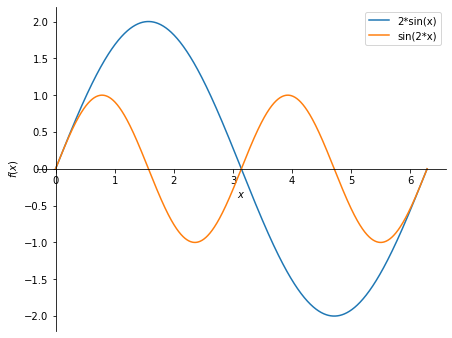

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(2 * sin(x), sin(2*x), (x, 0, 2*pi), legend=True);
```

</details>

#### Aufgabe 5.10

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(periodicity(sin(x), x))
display(periodicity(cos(2*pi*x), x))
diff(sin(x) + cos(x), x, 2)
```

In [ ]:
display(periodicity(sin(x), x))
display(periodicity(cos(2*pi*x), x))
diff(sin(x) + cos(x), x, 2)

## 6. Tangenten und Normalen

#### Tangente in einem Punkt

Die Tangente an den Graphen von f an der Stelle x₀ ist t(x) = f'(x₀) · (x − x₀) + f(x₀),
die **Normale** (senkrecht dazu) hat die Steigung −1 / f'(x₀).

In [ ]:
f = x * exp(-x)
x0 = 0
m = diff(f, x).subs(x, x0)
y0 = f.subs(x, x0)
display(m * (x - x0) + y0)
display(-1 / m * (x - x0) + y0)
plot(f, m * (x - x0) + y0, (x, -1, 4), ylim=(-1, 1));

#### Tangente durch einen Punkt außerhalb (Leistungsfach)

Gesucht sind Tangenten an f, die durch einen Punkt P(p | q) gehen, der **nicht** auf dem Graphen liegt. Man setzt die Tangente in
einem unbekannten Berührpunkt u an und verlangt, dass P auf ihr liegt: f'(u) · (p − u) + f(u) = q. Diese Gleichung löst man nach u.

In [ ]:
f = exp(x)
tang = diff(f, x).subs(x, u) * (x - u) + f.subs(x, u)
l = solve(Eq(tang.subs(x, 0), 0), u)
display(l)
tang.subs(u, l[0])

#### Aufgabe 6.1

Gib die Tangente an f(x) = eˣ an der Stelle x₀ = 1 aus (ausmultipliziert mit `expand`).

**Erwartete Ausgabe:**

$\displaystyle e x$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = exp(x)
expand(diff(f, x).subs(x, 1) * (x - 1) + f.subs(x, 1))
```

</details>

#### Aufgabe 6.2

Gib die Tangente an f(x) = sin(2x) an der Stelle x₀ = 0 aus.

**Erwartete Ausgabe:**

$\displaystyle 2 x$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = sin(2*x)
diff(f, x).subs(x, 0) * x + f.subs(x, 0)
```

</details>

#### Aufgabe 6.3

Gib die Tangente und die Normale an f(x) = x · eˣ an der Stelle x₀ = 0 aus.

**Erwartete Ausgabe:**

$\displaystyle x$

$\displaystyle - x$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x * exp(x)
m = diff(f, x).subs(x, 0)
display(m * x + f.subs(x, 0))
-1 / m * x + f.subs(x, 0)
```

</details>

#### Aufgabe 6.4

Gib die Tangente an f(x) = ln(x) an der Stelle x₀ = e aus und vereinfache mit `simplify`. **(Leistungsfach)**

**Erwartete Ausgabe:**

$\displaystyle \frac{x}{e}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = log(x)
simplify(diff(f, x).subs(x, E) * (x - E) + f.subs(x, E))
```

</details>

#### Aufgabe 6.5

An welcher Stelle hat f(x) = e^(2x) die Steigung 4? Gib die Stelle und die Tangente dort aus (Tangente mit `expand`).

**Erwartete Ausgabe:**

$\displaystyle \frac{\log{\left(2 \right)}}{2}$

$\displaystyle 4 x - 2 \log{\left(2 \right)} + 2$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = exp(2*x)
x0 = solve(Eq(diff(f, x), 4), x)[0]
display(x0)
expand(4 * (x - x0) + f.subs(x, x0))
```

</details>

#### Aufgabe 6.6

Berechne den Steigungswinkel der Tangente an f(x) = eˣ im Punkt (0 | 1) in Grad (`atan` und `deg`).

**Erwartete Ausgabe:**

$\displaystyle 45$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
deg(atan(diff(exp(x), x).subs(x, 0)))
```

</details>

#### Aufgabe 6.7

**(Leistungsfach)** Bestimme alle Tangenten an f(x) = x², die durch den Punkt P(1 | −3) gehen (Berührstellen u und Tangentengleichungen, ausmultipliziert).

**Erwartete Ausgabe:**

$\displaystyle \left[ -1, \  3\right]$

$\displaystyle \left[ - 2 x - 1, \  6 x - 9\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**2
tang = diff(f, x).subs(x, u) * (x - u) + f.subs(x, u)
l = solve(Eq(tang.subs(x, 1), -3), u)
display(l)
[expand(tang.subs(u, w)) for w in l]
```

</details>

#### Aufgabe 6.8

**(Leistungsfach)** Welche Tangente an f(x) = ln(x) geht durch den Ursprung? Gib die Berührstelle und die Tangente aus (`simplify`).

**Erwartete Ausgabe:**

$\displaystyle \left[ e\right]$

$\displaystyle \frac{x}{e}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = log(x)
tang = diff(f, x).subs(x, u) * (x - u) + f.subs(x, u)
l = solve(Eq(tang.subs(x, 0), 0), u)
display(l)
simplify(tang.subs(u, l[0]))
```

</details>

## 7. Grenzverhalten und Asymptoten

#### Grenzwerte für x → ±∞

`limit(f, x, oo)` berechnet den Grenzwert für x → ∞ (`oo` sind zwei kleine o und bedeuten ∞), `limit(f, x, -oo)` für x → −∞.
Ist der Grenzwert eine Zahl g, ist y = g eine **waagrechte Asymptote**.

Wichtig für e-Funktionen: e⁻ˣ → 0 für x → ∞, und eˣ wächst schneller als jede Potenz von x. Deshalb geht z. B. x² · e⁻ˣ → 0.

In [ ]:
display(limit(exp(-x), x, oo))
display(limit(x**2 * exp(-x), x, oo))
display(limit(x**2 * exp(-x), x, -oo))
limit(3 - 2 * exp(-x), x, oo)

#### Senkrechte Asymptoten (Polstellen)

An einer Definitionslücke (z. B. Nenner null) kann die Funktion gegen ±∞ gehen: eine **senkrechte Asymptote**.
`limit(f, x, 2, '+')` ist der Grenzwert von rechts, `limit(f, x, 2, '-')` von links. **Ohne Angabe rechnet sympy nur von rechts!**
Mit `'+-'` prüfst du beide Seiten: Unterscheiden sie sich, gibt sympy `zoo` aus (komplex unendlich, das heißt hier „kein Grenzwert“).

In [ ]:
f = 1 / (x - 2)
display(limit(f, x, 2, '+'), limit(f, x, 2, '-'))
display(limit(f, x, 2, '+-'))
display(limit(1 / (x - 2)**2, x, 2, '+-'))
plot(f, (x, -2, 6), ylim=(-6, 6));

#### Aufgabe 7.1

Berechne die Grenzwerte von f(x) = 2 + e⁻ˣ für x → ∞ und x → −∞.

**Erwartete Ausgabe:**

$\displaystyle 2$

$\displaystyle \infty$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = 2 + exp(-x)
display(limit(f, x, oo))
limit(f, x, -oo)
```

</details>

#### Aufgabe 7.2

Berechne die Grenzwerte von f(x) = x · eˣ für x → ∞ und x → −∞.

**Erwartete Ausgabe:**

$\displaystyle \infty$

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x * exp(x)
display(limit(f, x, oo))
limit(f, x, -oo)
```

</details>

#### Aufgabe 7.3

Berechne die Grenzwerte von f(x) = x³ · e^(−x) für x → ∞ und x → −∞.

**Erwartete Ausgabe:**

$\displaystyle 0$

$\displaystyle -\infty$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 * exp(-x)
display(limit(f, x, oo))
limit(f, x, -oo)
```

</details>

#### Aufgabe 7.4

Berechne den Grenzwert von f(x) = (2x² + 1)/(x² − 4) für x → ∞ (waagrechte Asymptote).

**Erwartete Ausgabe:**

$\displaystyle 2$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
limit((2*x**2 + 1) / (x**2 - 4), x, oo)
```

</details>

#### Aufgabe 7.5

Berechne für f(x) = (2x² + 1)/(x² − 4) die Grenzwerte bei x = 2 von links und von rechts.

**Erwartete Ausgabe:**

$\displaystyle -\infty$

$\displaystyle \infty$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = (2*x**2 + 1) / (x**2 - 4)
display(limit(f, x, 2, '-'))
limit(f, x, 2, '+')
```

</details>

#### Aufgabe 7.6

Prüfe mit `'+-'`, ob f(x) = 1/x² bzw. g(x) = 1/x bei x = 0 einen (beidseitigen) Grenzwert ∞ haben.

**Erwartete Ausgabe:**

$\displaystyle \infty$

$\displaystyle \tilde{\infty}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(limit(1 / x**2, x, 0, '+-'))
limit(1 / x, x, 0, '+-')
```

</details>

#### Aufgabe 7.7

**Medikament:** Die Konzentration im Blut ist c(t) = 20 · t · e^(−0,5t) (mg/l, t in Stunden; 0,5 als `Rational`). Berechne den Grenzwert für t → ∞,
den Zeitpunkt der höchsten Konzentration und diese Konzentration mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle 0$

$\displaystyle 2$

$\displaystyle 14.72$

In [ ]:
t = symbols('t', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
t = symbols('t', positive=True)
c = 20 * t * exp(-Rational(1, 2) * t)
display(limit(c, t, oo))
tmax = solve(diff(c, t), t)[0]
display(tmax)
N(c.subs(t, tmax), 4)
```

</details>

#### Aufgabe 7.8

Zeichne f(x) = 3 − 2 · e^(−x) und die Asymptote y = 3 für −1 ≤ x ≤ 5 in ein Diagramm.

**Erwartete Ausgabe:**



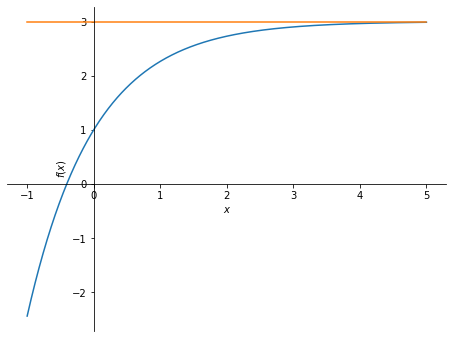

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(3 - 2 * exp(-x), 3, (x, -1, 5));
```

</details>

#### Aufgabe 7.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(limit(1 / x, x, oo))
display(limit(exp(x), x, -oo))
display(limit(exp(x) / x**10, x, oo))
limit(1 / x, x, 0)
```

In [ ]:
display(limit(1 / x, x, oo))
display(limit(exp(x), x, -oo))
display(limit(exp(x) / x**10, x, oo))
limit(1 / x, x, 0)

## 8. Gemischte Übungen

#### Aufgabe 8.1

Leite f(x) = (x² + 1) · e^(−x) ab, klammere aus und bestimme die Stellen mit waagrechter Tangente.

**Erwartete Ausgabe:**

$\displaystyle - \left(x - 1\right)^{2} e^{- x}$

$\displaystyle \left[ 1\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
fs = factor(diff((x**2 + 1) * exp(-x), x))
display(fs)
solve(fs, x)
```

</details>

#### Aufgabe 8.2

Leite f(x) = e^(sin x) ab.

**Erwartete Ausgabe:**

$\displaystyle e^{\sin{\left(x \right)}} \cos{\left(x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
diff(exp(sin(x)), x)
```

</details>

#### Aufgabe 8.3

Leite f(x) = √x · eˣ ab und klammere aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{\left(2 x + 1\right) e^{x}}{2 \sqrt{x}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
factor(diff(sqrt(x) * exp(x), x))
```

</details>

#### Aufgabe 8.4

Leite f(x) = sin(x²) und g(x) = sin²(x) ab (nicht verwechseln!).

**Erwartete Ausgabe:**

$\displaystyle 2 x \cos{\left(x^{2} \right)}$

$\displaystyle 2 \sin{\left(x \right)} \cos{\left(x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(diff(sin(x**2), x))
diff(sin(x)**2, x)
```

</details>

#### Aufgabe 8.5

Bestimme k so, dass f(x) = e^(kx) an der Stelle 0 die Steigung 3 hat.

**Erwartete Ausgabe:**

$\displaystyle \left[ 3\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solve(Eq(diff(exp(k*x), x).subs(x, 0), 3), k)
```

</details>

#### Aufgabe 8.6

Prüfe, dass f(x) = 5 · e^(−2x) die Gleichung f'(x) = −2 · f(x) erfüllt (`simplify(f' + 2·f)` muss 0 sein).

**Erwartete Ausgabe:**

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = 5 * exp(-2*x)
simplify(diff(f, x) + 2 * f)
```

</details>

#### Aufgabe 8.7

Prüfe, dass f(x) = sin(3x) die Gleichung f''(x) = −9 · f(x) erfüllt.

**Erwartete Ausgabe:**

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = sin(3*x)
simplify(diff(f, x, 2) + 9 * f)
```

</details>

#### Aufgabe 8.8

Ein Schüler hat für f(x) = x · e^(2x) die Ableitung f'(x) = e^(2x) + 2x · e^(2x) angegeben, eine Schülerin (1 + 2x) · e^(2x). Prüfe beide mit `simplify(... - f')`.

**Erwartete Ausgabe:**

$\displaystyle 0$

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
fs = diff(x * exp(2*x), x)
display(simplify(exp(2*x) + 2*x*exp(2*x) - fs))
simplify((1 + 2*x) * exp(2*x) - fs)
```

</details>

#### Aufgabe 8.9

**Population:** Eine Bakterienkultur wächst nach N(t) = 500 · e^(0,3t) (t in Stunden; 0,3 als `Rational`). Wann sind es 5000 Bakterien (4 Ziffern)?
Wie schnell wächst die Kultur zu diesem Zeitpunkt (Bakterien pro Stunde)?

**Erwartete Ausgabe:**

$\displaystyle 7.675$

$\displaystyle 1500$

In [ ]:
t = symbols('t', real=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
t = symbols('t', real=True)
N_t = 500 * exp(Rational(3, 10) * t)
t1 = solve(Eq(N_t, 5000), t)[0]
display(N(t1, 4))
simplify(diff(N_t, t).subs(t, t1))
```

</details>